UPDATE WITH NEW SLEEP DATA AFTER CHANGING DEDUPLICATION METHOD !!!!!!!!!

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
phq8 = pd.read_csv("./data_cleaned/phq8_data.csv")

In [41]:
sleep = pd.read_csv("./data_cleaned/sleep_data.csv")

In [42]:
total_dataset = pd.read_stata("./data/totaldataset.dta")

/var/folders/bt/f2dk62zd4lv80vqdphjgmw840000gn/T/ipykernel_15803/4226013150.py:1: UserWarning: Encountered %tC format. Leaving in Stata Internal Format.
  total_dataset = pd.read_stata("./data/totaldataset.dta")


In [43]:
sleep.head()

,participant_name,timeInterval_ID,date,total_sleep_time,time_in_bed,light_pct,deep_pct,REM_pct,awake_pct,NREM_pct,sleep_onset,sleep_offset,rem_latency,sleep_efficiency,awakenings,insomnia,hypersomnia
0,007751c5-d7ad-4bec-a58f-abf32500e2ae,1208,2019-04-12,19410,21030,60.199715,17.974322,14.122682,7.703281,78.174037,3.583333,9.350000,3.025000,92.296719,1,0,0
1,007751c5-d7ad-4bec-a58f-abf32500e2ae,1209,2019-04-13,16350,18300,45.737705,26.393443,17.213115,10.655738,72.131148,3.566667,8.633333,4.175000,89.344262,3,0,0
2,007751c5-d7ad-4bec-a58f-abf32500e2ae,1210,2019-04-14,23490,25110,42.771804,24.731183,26.045400,6.451613,67.502987,2.800000,9.616667,2.191667,93.548387,1,0,0
3,007751c5-d7ad-4bec-a58f-abf32500e2ae,1211,2019-04-15,13770,15210,51.479290,28.007890,11.045365,9.467456,79.487179,23.816667,4.050000,1.883333,90.532544,2,0,0
4,007751c5-d7ad-4bec-a58f-abf32500e2ae,1214,2019-04-18,24180,26790,55.767077,21.612542,12.877940,9.742441,77.379619,2.350000,9.783333,3.208333,90.257559,2,0,0


In [44]:
phq8.head()

,participant_name,timeInterval_ID,date,total_score,start_date,period_index,ref_date,diff_days
0,007751c5-d7ad-4bec-a58f-abf32500e2ae,1113,2019-01-07,9,2019-01-07,0,2019-01-07,0
1,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,2019-12-18,1,2019-03-27,19,2019-12-18,0
2,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1472,2020-01-01,1,2019-03-27,20,2020-01-01,0
3,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1486,2020-01-15,3,2019-03-27,21,2020-01-15,0
4,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1514,2020-02-12,11,2019-03-27,23,2020-02-12,0


create a dataframe where for each 2 week period prior to each phq8 measurement for each participant, the number of missing sleep dates is recorded.


In [45]:
sleep_obs = sleep[['participant_name', 'timeInterval_ID']].copy()
sleep_obs['observed'] = 1

In [46]:
# Expand each PHQ-8 row into 14 prior days
window = phq8[['participant_name', 'timeInterval_ID']].copy()

window = window.loc[window.index.repeat(14)].copy()
window['lag'] = list(range(1, 15)) * len(phq8)

# Compute the prior day IDs
window['timeInterval_ID_window'] = window['timeInterval_ID'] - window['lag']

In [47]:
window = window.merge(
    sleep_obs,
    left_on=['participant_name', 'timeInterval_ID_window'],
    right_on=['participant_name', 'timeInterval_ID'],
    how='left'
)

In [48]:
window = window.rename(columns={'timeInterval_ID_x': 'timeInterval_ID'})

In [49]:
window['missing'] = window['observed'].isna().astype(int)

missing_counts = (
    window.groupby(['participant_name', 'timeInterval_ID'])
    ['missing']
    .sum()
    .reset_index(name='sleep_missing_last14')
)

In [50]:
phq8_with_missing = phq8.merge(
    missing_counts,
    on=['participant_name', 'timeInterval_ID'],
    how='left'
)

In [51]:
# percentage of participants with <K days missing for all PHQ8 Periods
K = 13

participant_ok = (
    phq8_with_missing
    .assign(ok = phq8_with_missing['sleep_missing_last14'] < K)
    .groupby('participant_name')['ok']
    .all()
    .reset_index()
)

percentage = participant_ok['ok'].mean() * 100
percentage

8.235294117647058

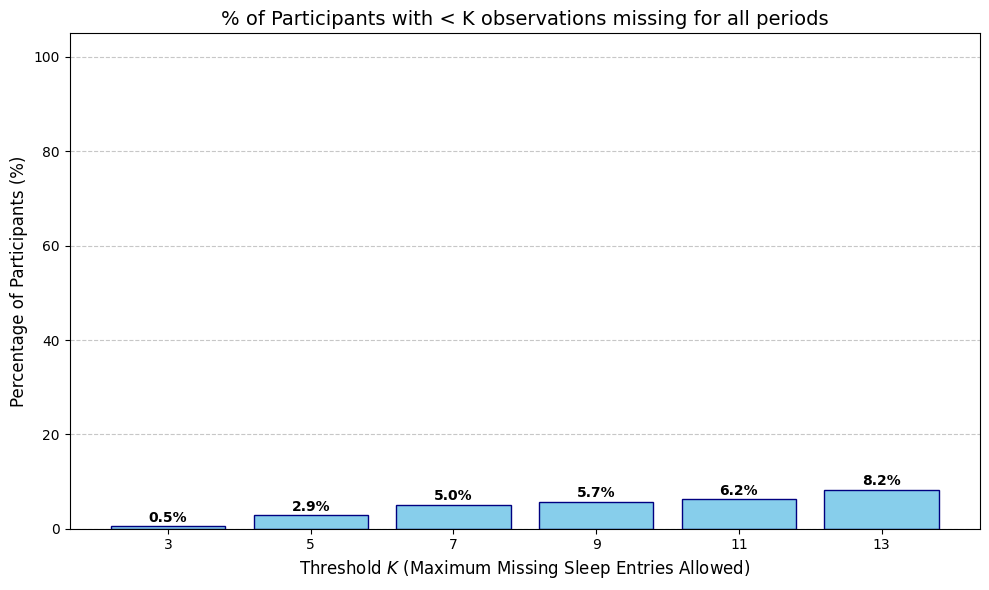

In [53]:
# 1. Define the range of K values to test
k_values = [3, 5, 7, 9, 11, 13]
results = []

# 2. Iterate through each K and calculate the percentage
for k in k_values:
    # Apply your logic for the current K
    participant_ok = (
        phq8_with_missing
        .assign(ok = phq8_with_missing['sleep_missing_last14'] < k)
        .groupby('participant_name')['ok']
        .all()
        .reset_index()
    )
    
    # Calculate percentage and store it
    percentage = participant_ok['ok'].mean() * 100
    results.append(percentage)

# 3. Plot the results
plt.figure(figsize=(10, 6))
plt.bar([str(k) for k in k_values], results, color='skyblue', edgecolor='navy')

# Add labels and styling
plt.xlabel('Threshold $K$ (Maximum Missing Sleep Entries Allowed)', fontsize=12)
plt.ylabel('Percentage of Participants (%)', fontsize=12)
plt.title('% of Participants with < K observations missing for all periods', fontsize=14)
plt.ylim(0, 105)  # Set limit slightly above 100 for visual clarity

# Add data labels on top of bars
for i, v in enumerate(results):
    plt.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

In [62]:
K = 9      # threshold for missing days
X = 0.5    # required proportion (e.g., 80%)

# Step 1: mark each period as "good"
df = phq8_with_missing.copy()
df['good'] = df['sleep_missing_last14'] < K

# Step 2: compute proportion of good periods per participant
participant_stats = (
    df.groupby('participant_name')['good']
    .mean()
    .reset_index(name='prop_good_periods')
)

# Step 3: check which participants meet the X% requirement
participant_stats['meets_threshold'] = (
    participant_stats['prop_good_periods'] >= X
)

# Step 4: compute percentage of participants
percentage = participant_stats['meets_threshold'].mean() * 100

print(f"{percentage:.2f}% of participants have at least {X*100}% of periods where less than {K} days are missing")

67.06% of participants have at least 50.0% of periods where less than 9 days are missing


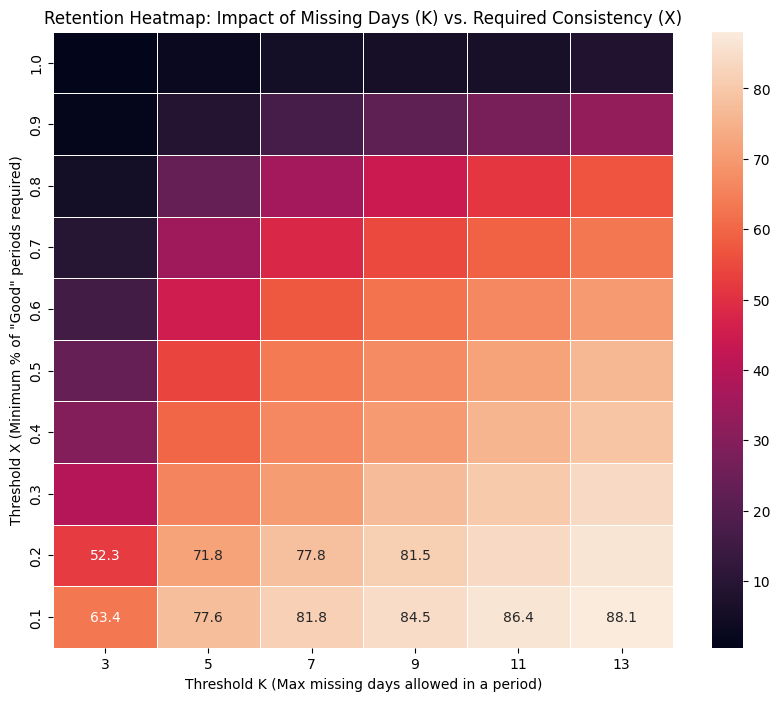

In [68]:
# 1. Define the ranges for both parameters
k_values = [3, 5, 7, 9, 11, 13]
x_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

# 2. Initialize a list to store results
heatmap_data = []

# 3. Nested loop to test every combination
for k in k_values:
    for x in x_values:
        # Mark periods as good
        df_temp = phq8_with_missing.copy()
        df_temp['good'] = df_temp['sleep_missing_last14'] < k
        
        # Compute proportion of good periods per participant
        participant_stats = (
            df_temp.groupby('participant_name')['good']
            .mean()
            .reset_index()
        )
        
        # Check if participant meets the consistency threshold X
        percentage = (participant_stats['good'] >= x).mean() * 100
        
        # Append results
        heatmap_data.append({'K': k, 'X': x, 'Retention': percentage})

# 4. Transform data into a matrix format for the heatmap
df_heatmap = pd.DataFrame(heatmap_data)
pivot_table = df_heatmap.pivot(index="X", columns="K", values="Retention")

# 5. Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table, annot=True, fmt=".1f",linewidths=.5)
# Formatting
plt.title('Retention Heatmap: Impact of Missing Days (K) vs. Required Consistency (X)')
plt.xlabel('Threshold K (Max missing days allowed in a period)')
plt.ylabel('Threshold X (Minimum % of "Good" periods required)')
plt.gca().invert_yaxis() # Puts higher requirements at the top

In [60]:
pivot_table

K,3,5,7,9,11,13
X,,,,,,
0.1,63.361345,77.647059,81.848739,84.537815,86.386555,88.067227
0.2,52.268908,71.764706,77.815126,81.512605,83.865546,86.386555
0.3,39.663866,65.546218,70.588235,77.310924,80.504202,83.697479
0.4,29.747899,59.831933,66.386555,70.084034,75.462185,79.159664
0.5,23.529412,53.949580,63.697479,67.058824,71.932773,76.134454
0.6,15.966387,45.042017,57.310924,62.184874,66.386555,70.252101
0.7,9.411765,35.294118,48.235294,54.621849,59.159664,63.193277
0.8,5.042017,23.697479,36.302521,44.033613,51.260504,56.638655
0.9,1.344538,8.739496,16.806723,21.848739,27.226891,32.941176


In [2]:
import pandas as pd

In [3]:
final_data = pd.read_csv("./data_cleaned/final_dataset.csv")

In [4]:
final_data

,participant_name,timeInterval_ID,phq8_score,sleep_missing_last14,sleep_min,sleep_max,sleep_mean,sleep_median,sleep_std,sleep_iqr,...,audit_2,audit_3,audit_4,audit_5,audit_6,audit_7,audit_8,audit_9,audit_10,depression_medication
0,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,7 to 9,Less than monthly,Less than monthly,Never,Never,Less than monthly,Never,No,No,NaN
1,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
2,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60063,5e836448-4f14-468d-9ab8-18189c169fca,1496,4,5,10290.0,27900.0,16433.333333,13620.0,6478.398722,11490.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes
60064,5e836448-4f14-468d-9ab8-18189c169fca,1496,4,5,10290.0,27900.0,16433.333333,13620.0,6478.398722,11490.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes
60065,5e836448-4f14-468d-9ab8-18189c169fca,1496,4,5,10290.0,27900.0,16433.333333,13620.0,6478.398722,11490.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes
60066,5e836448-4f14-468d-9ab8-18189c169fca,1496,4,5,10290.0,27900.0,16433.333333,13620.0,6478.398722,11490.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes


In [5]:
final_data[final_data["participant_name"] == "9078ae18-c644-4cdb-a582-6a2aa671ecb4"]

,participant_name,timeInterval_ID,phq8_score,sleep_missing_last14,sleep_min,sleep_max,sleep_mean,sleep_median,sleep_std,sleep_iqr,...,audit_2,audit_3,audit_4,audit_5,audit_6,audit_7,audit_8,audit_9,audit_10,depression_medication
0,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,7 to 9,Less than monthly,Less than monthly,Never,Never,Less than monthly,Never,No,No,NaN
1,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
2,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1458,1,4,10560.0,30390.0,24657.000000,26070.0,6000.957424,5962.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59805,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1796,13,7,12480.0,27000.0,22268.571429,23610.0,5182.008711,5115.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59806,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1796,13,7,12480.0,27000.0,22268.571429,23610.0,5182.008711,5115.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59807,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1796,13,7,12480.0,27000.0,22268.571429,23610.0,5182.008711,5115.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59808,9078ae18-c644-4cdb-a582-6a2aa671ecb4,1796,13,7,12480.0,27000.0,22268.571429,23610.0,5182.008711,5115.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
